# Plasma-input distribution-volume imaging

## 1. Problem
Dynamic PET follows tracer exchange rather than only spatial activity. We reconstruct the total distribution-volume field $V$ in mL plasma per mL tissue from a real [11C]PS13 baseline acquisition. This is a kinetic spatial inverse problem; the output is not static PET activity or receptor density. There is no independently measured voxelwise distribution-volume truth.

The selected method is the arterial-input graphical relation introduced by Logan et al. (1990), DOI: 10.1038/jcbfm.1990.127. The unchanged author implementation is dynamicpet's weighted graphical fit with `k2prime=None`. Its class and returned parameter use reference-tissue terminology (`LRTM`, `DVR`); when the supplied input is arterial parent plasma, the identical executed algebra estimates total distribution volume $V$, not a tissue ratio. No reference region or subtraction of one is introduced.

In [1]:
from pathlib import Path
import sys,time,json,os
import numpy as np
import matplotlib.pyplot as plt
root=Path.cwd()
if not (root/'src').exists():root=root.parent
os.chdir(root)
sys.path.insert(0,str(root))
from src.preprocessing import load_data,parent_input
from src.physics_model import cumulative_integral,transformed_data,linear_relative_residual
from src.solvers import reconstruct
from src import visualization as vis
activity,mask,plasma,start,duration,raw=load_data()
reference=np.load('notebooks/reference_outputs/upstream_measurements.npz',allow_pickle=False)['reconstruction'][0]
print('Bound observations:',activity.shape,'included voxels:',int(mask.sum()))
print('All 27 native frames; central native slice z=55; no spatial interpolation.')

Bound observations: (1, 200, 200, 27) included voxels: 5029
All 27 native frames; central native slice z=55; no spatial interpolation.


## 2. Data
The OpenNeuro ds004868 v1.0.1 acquisition supplies all 27 frames over 90 minutes, 19 arterial plasma samples, and parent-tracer fractions. The complete central native 200×200 slice is retained. Pixel spacing is 2.0364201068878174 mm in-plane and the original slice spacing is 2 mm. Public support is determined from observed late activity (last ten frames mean at least 1000 Bq/mL and all selected late frames positive), giving 5029 voxels. It contains no reference-derived segmentation. Exterior values are fixed to zero.

Images and blood use the supplied common decay-to-injection reference; an additional decay or dose factor would corrupt the concentration ratio. Parent plasma is the measured plasma concentration multiplied by its measured parent fraction, then linearly interpolated to frame midpoints with a preinjection zero. This calibration is supplied independently of the kinetic fit, not estimated from a hidden volume map.

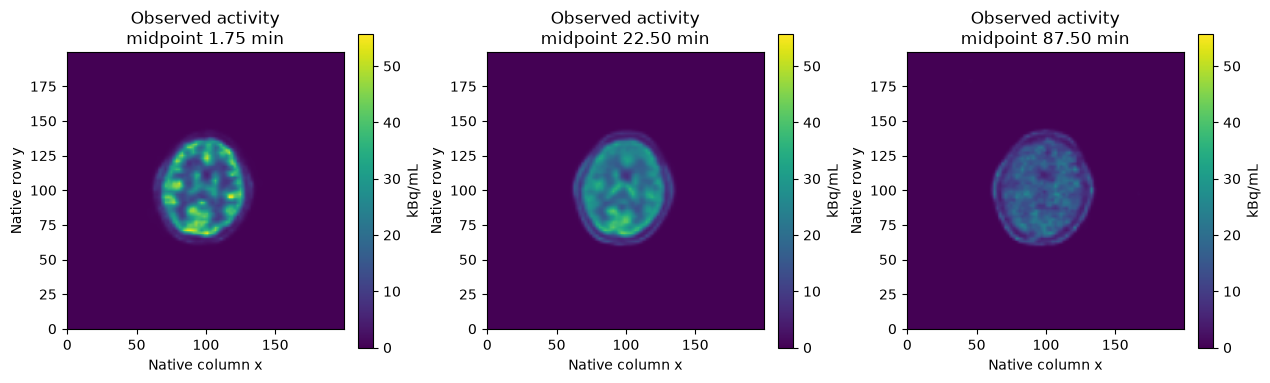

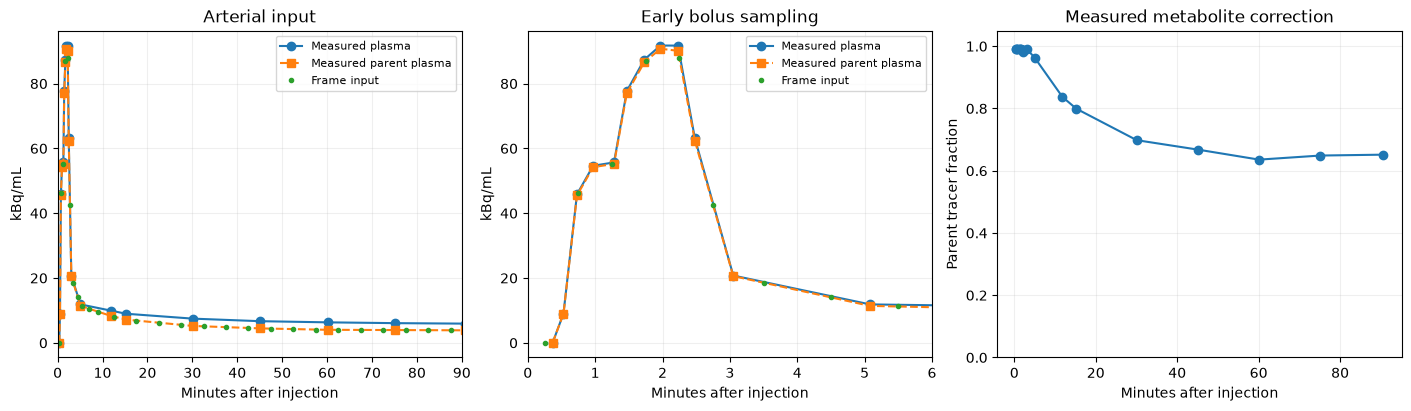

In [2]:
selected_frames=[3,13,26]
vis.maps([activity[0,:,:,k]/1000 for k in selected_frames],
         [f'Observed activity\nmidpoint {start[k]+duration[k]/2:.2f} min' for k in selected_frames],
         '01_observed_dynamic_activity','kBq/mL',shared=True)
plt.show()
vis.arterial(raw,plasma,start,duration);plt.show()

## 3. Physics
For reversible kinetics at sufficiently late times,

$$Y(r,t)=\frac{\int_0^t C(r,s)ds}{C(r,t)}
=V(r)\frac{\int_0^t C_P(s)ds}{C(r,t)}+b(r)=V(r)X(r,t)+b(r).$$

$C$ is tissue concentration, $C_P$ is parent-plasma concentration, $r$ is voxel position, and $s,t$ are times. $X,Y,b$ have units of minutes; $V$ has units of mL plasma per mL tissue. The intercept absorbs the late kinetic transient. The relation is asymptotic and noisy ratios can bias the fitted slope. It does not assume one anatomical region is free of specific tracer binding.

The bound implementation approximates the integrals using trapezoids between frame midpoints. Its first integral is zero for this injection-start acquisition. The upstream docstring describes frame-end integration, but its executed code uses midpoints; we preserve the executed convention and explicitly test it. This omits the initial half-frame area. A separately labeled sensitivity adds an initial triangular area, and does not replace the selected method.

In [3]:
x,y,w=transformed_data(activity[mask],plasma,start,duration)
print('Fit uses frame starts >=30 min:',int(len(w)),'frames')
print('Initial tissue and plasma integral:',float(cumulative_integral(activity[mask][0],start,duration)[0]),float(cumulative_integral(plasma,start,duration)[0]))
print('All integrations use all frames before selecting the late window.')

Fit uses frame starts >=30 min: 12 frames
Initial tissue and plasma integral: 0.0 0.0
All integrations use all frames before selecting the late window.


## 4. Method
For each included voxel form a two-column matrix $A=[1,X]$ and response $Y$. Frame-duration weights form $W=\mathrm{diag}(w)$ with durations in minutes. Solve

$$\begin{bmatrix}b\\V\end{bmatrix}=(A^TWA)^{-1}A^TWY.$$

The code evaluates the original symmetric 2×2 linear-system solve rather than explicitly forming a matrix inverse. No spatial regularization, positivity constraint, clipping, iteration or fitted global scaling is added. Original singular-system fallback and identical-input behavior are retained and tested; neither determines the selected real-data estimates. The fit starts at 30 minutes; all integrals include the earlier observations. This is an unregularized published baseline with limitations from noise, plasma sampling, finite integration and incomplete late equilibration.

{
  "fresh_seconds": 0.3805028000060702,
  "agreement_with_reproduced_original": {
    "ncc": 0.9999999999999999,
    "nrmse": 0.0
  },
  "late_linear_relative_weighted_residual": 0.061964590066854765
}


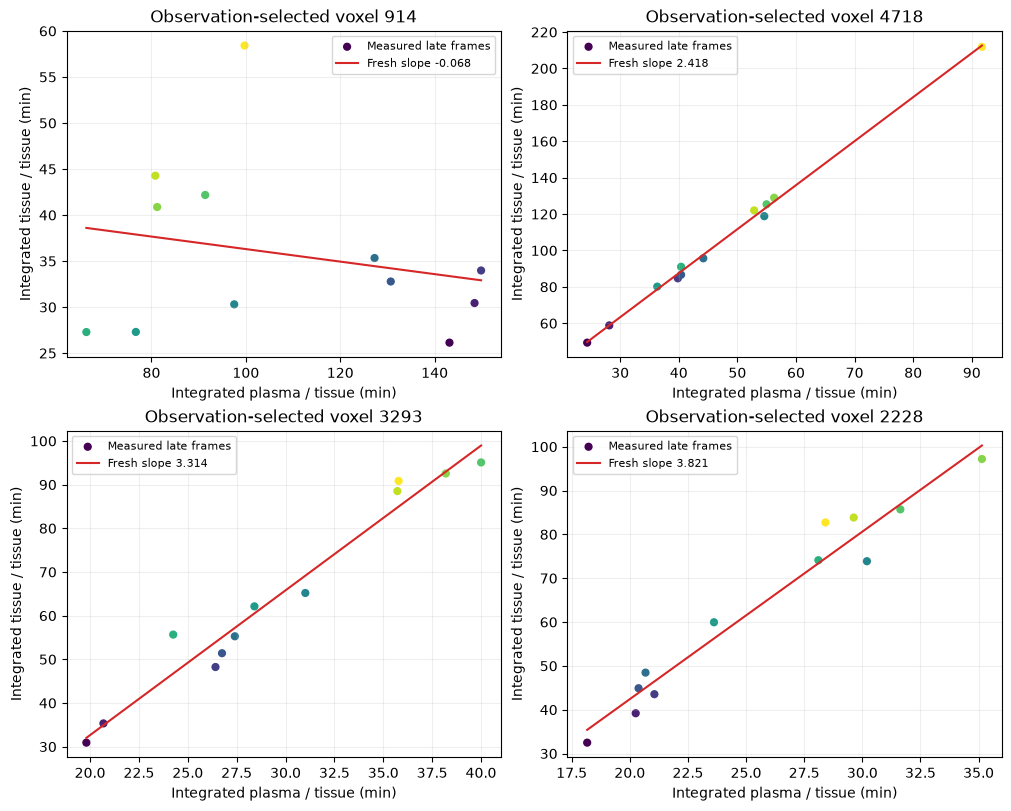

In [4]:
begin=time.perf_counter()
volume,offset=reconstruct(activity,mask,plasma,start,duration)
runtime=time.perf_counter()-begin
Path('output').mkdir(exist_ok=True)
np.savez_compressed('output/reconstruction.npz',reconstruction=volume[None])
agreement=vis.metrics(volume[mask],reference[mask])
relative,eliminated,residual=linear_relative_residual(volume,activity,mask,plasma,start,duration)
print(json.dumps(dict(fresh_seconds=runtime,agreement_with_reproduced_original=agreement,late_linear_relative_weighted_residual=relative),indent=2))
# Choose examples by observed late activity quantiles, without consulting fitted V.
late_activity=activity[...,start>=30].mean(-1)
order=np.argsort(late_activity[mask]);examples=order[(np.array([.1,.35,.65,.9])*(len(order)-1)).astype(int)]
vis.transformed_fits(x,y,w,volume[mask],offset[mask],examples);plt.show()

## 5. Results
The first comparison is between this task's reproduced unmodified author code and the fresh local reconstruction on exactly the same observations and support. The author result is a standard-method reference, not tissue truth. The difference is expected to be numerically zero because the same quadrature, weighting, units and solver are preserved. The other figures examine observed contrast, model mismatch, late-window sensitivity and calibration assumptions using fresh computations.

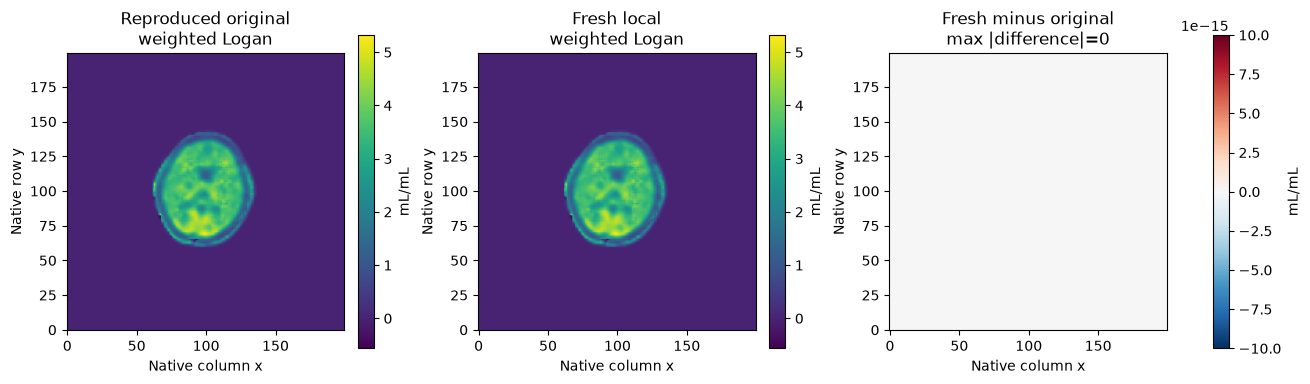

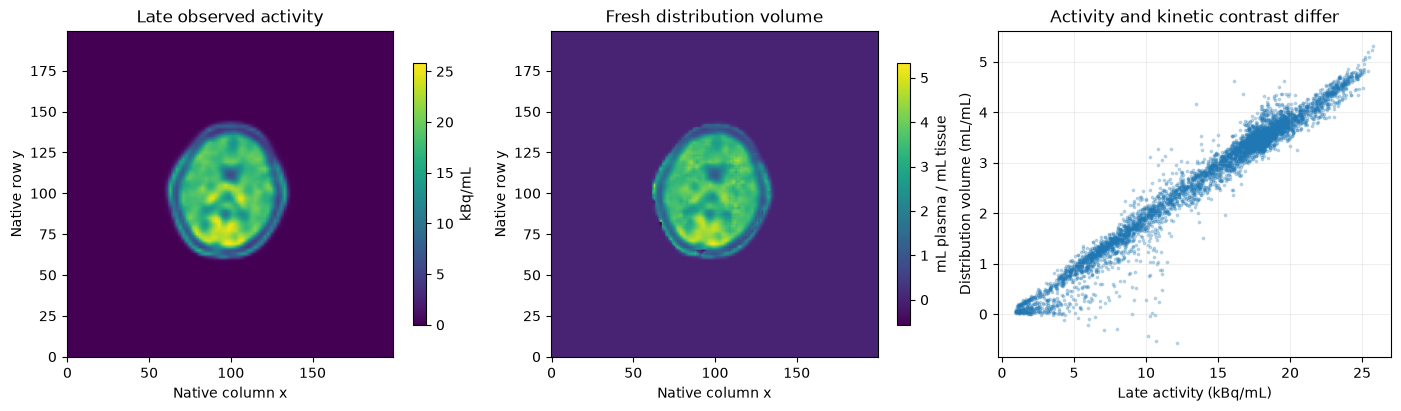

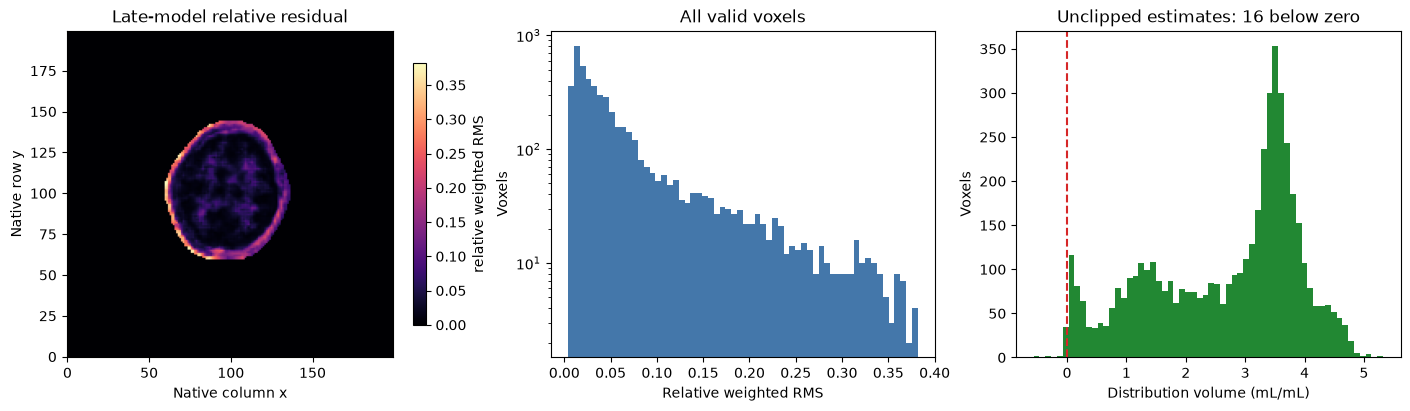

16/5029 included estimates are negative (0.318%). They are retained, not erased or masked after fitting.


In [5]:
fig,axes=plt.subplots(1,3,figsize=(13,4),layout='constrained')
lo=float(min(reference.min(),volume.min()));hi=float(max(reference.max(),volume.max()))
for ax,a,title in zip(axes[:2],[reference[0],volume[0]],['Reproduced original\nweighted Logan','Fresh local\nweighted Logan']):
    im=ax.imshow(a,origin='lower',cmap='viridis',vmin=lo,vmax=hi,rasterized=True);ax.set(title=title,xlabel='Native column x',ylabel='Native row y');fig.colorbar(im,ax=ax,label='mL/mL',shrink=.8)
difference=volume[0]-reference[0];lim=max(float(abs(difference).max()),1e-14)
im=axes[2].imshow(difference,origin='lower',cmap='RdBu_r',vmin=-lim,vmax=lim,rasterized=True)
axes[2].set(title=f'Fresh minus original\nmax |difference|={abs(difference).max():.2g}',xlabel='Native column x',ylabel='Native row y');fig.colorbar(im,ax=axes[2],label='mL/mL',shrink=.8)
vis.save(fig,'04_original_and_fresh_comparison');plt.show()
vis.activity_volume(late_activity[0],volume[0],mask[0]);plt.show()
_,local_residual=vis.residual_figure(residual,y,w,mask,volume);plt.show()
negative=int(np.count_nonzero(volume[mask]<0))
print(f'{negative}/{mask.sum()} included estimates are negative ({100*negative/mask.sum():.3f}%). They are retained, not erased or masked after fitting.')

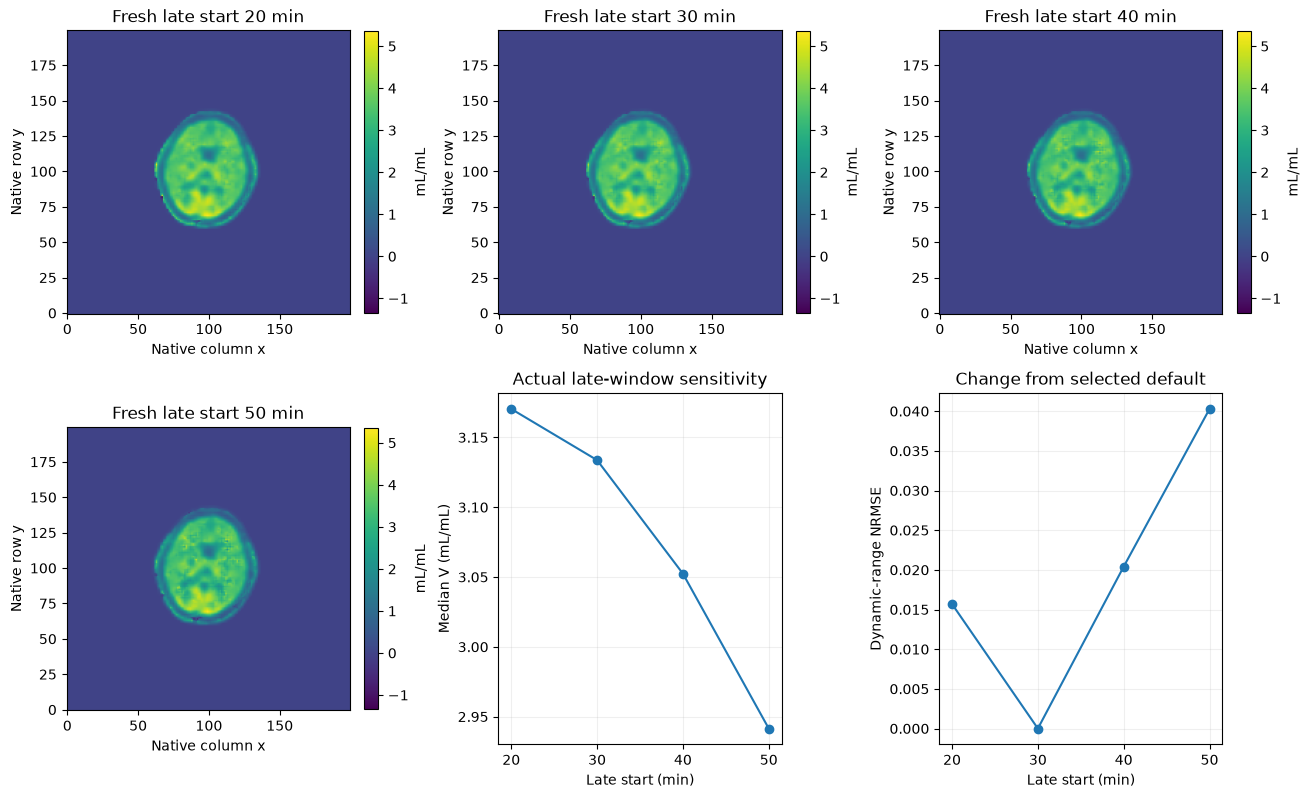

[
  {
    "start": 20,
    "median": 3.1703888472585917,
    "nrmse_vs_default": 0.01568824826337308,
    "relative_residual": 0.07069151252674945,
    "seconds": 0.466163700009929
  },
  {
    "start": 30,
    "median": 3.13372989831101,
    "nrmse_vs_default": 0.0,
    "relative_residual": 0.061964590066854765,
    "seconds": 0.45823650000966154
  },
  {
    "start": 40,
    "median": 3.0524012826680162,
    "nrmse_vs_default": 0.020408475869015622,
    "relative_residual": 0.05251270243008366,
    "seconds": 0.45431899999675807
  },
  {
    "start": 50,
    "median": 2.941492209424372,
    "nrmse_vs_default": 0.040280325821750174,
    "relative_residual": 0.042184571152298636,
    "seconds": 0.46056949999183416
  }
]
Later starts reduce the fitted residual but also change V: smaller residual alone is not evidence of an unbiased estimate.


In [6]:
late_maps={};late_rows=[]
for tstar in [20,30,40,50]:
    begin=time.perf_counter();v,b=reconstruct(activity,mask,plasma,start,duration,tstar=tstar);seconds=time.perf_counter()-begin
    r,_,_=linear_relative_residual(v,activity,mask,plasma,start,duration,tstar=tstar)
    late_maps[tstar]=v
    late_rows.append(dict(start=tstar,median=float(np.median(v[mask])),nrmse_vs_default=vis.metrics(v[mask],volume[mask])['nrmse'],relative_residual=r,seconds=seconds))
vis.late_sensitivity(late_maps,late_rows);plt.show()
print(json.dumps(late_rows,indent=2))
print('Later starts reduce the fitted residual but also change V: smaller residual alone is not evidence of an unbiased estimate.')

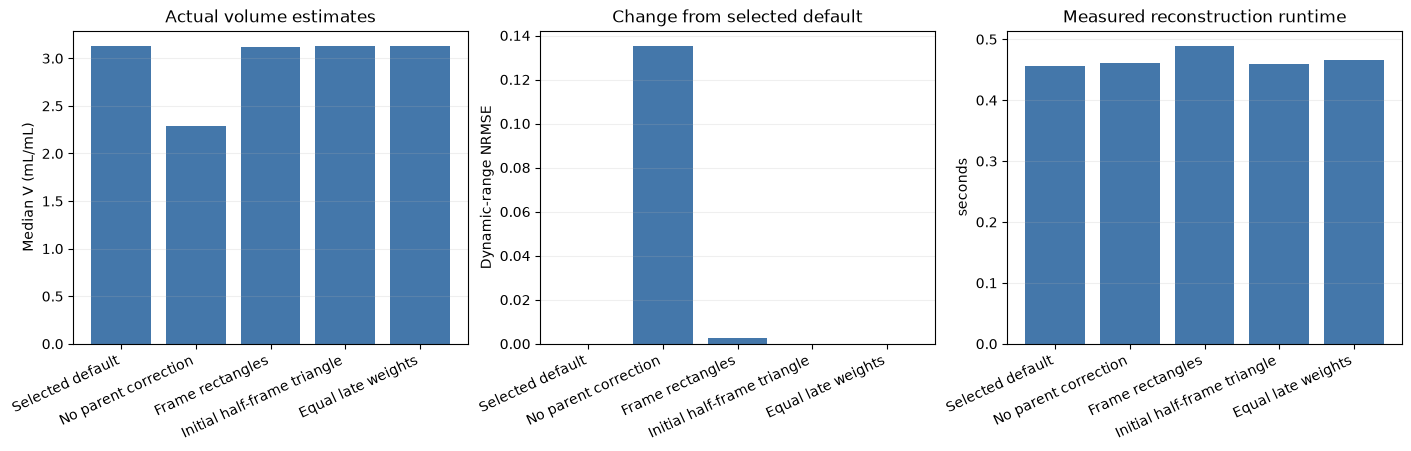

[
  {
    "label": "Selected default",
    "median": 3.13372989831101,
    "nrmse_vs_default": 0.0,
    "seconds": 0.45536570000695065
  },
  {
    "label": "No parent correction",
    "median": 2.2918092433634722,
    "nrmse_vs_default": 0.13542538622943626,
    "seconds": 0.46091639999940526
  },
  {
    "label": "Frame rectangles",
    "median": 3.123242579847447,
    "nrmse_vs_default": 0.0026741493396788005,
    "seconds": 0.4895994999969844
  },
  {
    "label": "Initial half-frame triangle",
    "median": 3.133723712138723,
    "nrmse_vs_default": 4.943188975184789e-06,
    "seconds": 0.45939639999414794
  },
  {
    "label": "Equal late weights",
    "median": 3.133729898310976,
    "nrmse_vs_default": 3.2419755692641745e-15,
    "seconds": 0.4654049000091618
  }
]
The no-parent-correction branch deliberately violates the supplied calibration and is a sensitivity diagnostic. The initial-triangle branch is a local diagnostic extension. Equal late weights coincide because all sel

In [7]:
assumptions={};assumption_rows=[]
uncorrected=parent_input(raw['blood_time'][0],raw['plasma_activity'][0],np.ones(19),raw['frame_start'][0],raw['frame_duration'][0])
for label,cp,quadrature,weight in [('Selected default',plasma,'trapz','frame_duration'),('No parent correction',uncorrected,'trapz','frame_duration'),('Frame rectangles',plasma,'rect','frame_duration'),('Initial half-frame triangle',plasma,'trapz_injection','frame_duration'),('Equal late weights',plasma,'trapz',None)]:
    begin=time.perf_counter();v,b=reconstruct(activity,mask,cp,start,duration,integration_type=quadrature,weight_by=weight);seconds=time.perf_counter()-begin
    assumptions[label]=v
    assumption_rows.append(dict(label=label,median=float(np.median(v[mask])),nrmse_vs_default=vis.metrics(v[mask],volume[mask])['nrmse'],seconds=seconds))
vis.assumption_sensitivity(assumption_rows);plt.show()
print(json.dumps(assumption_rows,indent=2))
print('The no-parent-correction branch deliberately violates the supplied calibration and is a sensitivity diagnostic. The initial-triangle branch is a local diagnostic extension. Equal late weights coincide because all selected late frames have equal duration.')

In [8]:
import importlib.util
spec=importlib.util.spec_from_file_location('standalone_judge',root/'evaluation/judge.py');judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
report=judge.evaluate(root/'output/reconstruction.npz')
Path('output/judge_report.json').write_text(json.dumps(report,indent=2,allow_nan=False),encoding='utf-8')
assert report['passed'],report
print(json.dumps(report,indent=2))
if os.environ.get('IMAGING_FIGURE_DIR'):
    private=Path(os.environ['IMAGING_FIGURE_DIR'])
    np.savez_compressed(private/'numerical_sources.npz',observed_activity=activity,mask=mask,plasma=plasma,frame_start=start,frame_duration=duration,original=reference,fresh=volume,intercept=offset,transformed_design=x,transformed_response=y,weights=w,residual=residual,local_relative_residual=local_residual,example_indices=examples,**{f'late_{k}':v for k,v in late_maps.items()},**{f'assumption_{k}':v for k,v in enumerate(assumptions.values())})
    (private/'scientific_measurements.json').write_text(json.dumps(dict(fresh_seconds=runtime,agreement=agreement,late_linear_relative_weighted_residual=relative,negative_count=negative,late_sensitivity=late_rows,assumption_sensitivity=assumption_rows,judge=report),indent=2,allow_nan=False),encoding='utf-8')

{
  "status": "pass",
  "passed": true,
  "metrics": {
    "ncc": 0.9999999999999999,
    "nrmse": 0.0,
    "late_linear_relative_weighted_residual": 0.061964590066854765
  },
  "thresholds": {
    "ncc": {
      "comparison": ">=",
      "boundary": 0.999999
    },
    "nrmse": {
      "comparison": "<=",
      "boundary": 1e-07
    },
    "late_linear_relative_weighted_residual": {
      "comparison": "<=",
      "boundary": 0.06258423596752331
    }
  },
  "errors": []
}


## 6. Conclusion
The fresh local implementation reproduces the original weighted graphical fit on all 5029 bound voxel time courses. Spatial kinetic contrast differs from late activity contrast. Actual late-window and plasma-calibration comparisons show that a reproducible map remains conditional on the arterial input, metabolite correction and asymptotic linear regime. The 16 negative estimates, substantial local residuals and sensitivity to the start window are scientific limitations of this unregularized noisy-data baseline, not hidden failures to remove. No biological ground truth or newly reproduced comparison method is claimed.

The canonical notebook actively reconstructs the complete selected slice. The upstream library is never imported by its execution path. Provenance, independent original fixtures, physical checks and the standalone output contract are recorded in `test/validation.md`.